<a href="https://colab.research.google.com/github/J0n4ta/Trabalhos-Universit-rios-e-Projetos-Pessoais/blob/main/Classifica%C3%A7%C3%A3o_de_Imagens_CIFAR_10_e_PyTorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Importações**

In [ ]:
import torch
import torch.utils
import torch.utils.data
import torchvision
import torchvision.transforms as transformers
from matplotlib import pyplot as plt
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score,recall_score, f1_score, precision_score
import seaborn as sns
import numpy as np

#**Carregando Dataset**
**Após Carregar o Dataset, carregará os dados de teste em "caixas"(batchs) e embaralhando(shuffle).**

In [ ]:
transform = transformers.Compose([transformers.ToTensor(),transformers.Normalize((0.5),(0.5))])

train_dataset = torchvision.datasets.CIFAR10(root = "./data",transform=transform, train=True, download=True)
test_dataset = torchvision.datasets.CIFAR10(root = "./data",transform=transform, train=False, download=True)

train_loader = torch.utils.data.DataLoader(dataset = train_dataset, batch_size=32, shuffle=True)
test_loader = torch.utils.data.DataLoader(dataset=test_dataset, batch_size=32, shuffle=False)

#**Lista para Classificação**

In [ ]:
#criando um dicionario para as imagens
dicionario = {
    0: "airplane",
    1: "automobile",
    2: "bird",
    3: "cat",
    4: "deer",
    5: "dog",
    6: "frog",
    7: "horse",
    8: "ship",
    9: "truck"
}

#**Imprimindo Imagens e Classificando**

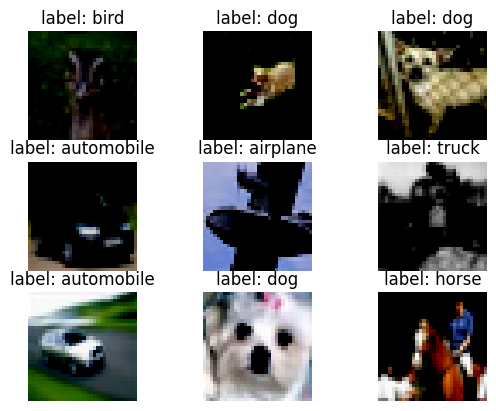

In [ ]:
examples = iter(train_loader)
images, labels = next(examples)

for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(images[i].permute(1,2,0))
    plt.title(f"label: {dicionario[labels[i].item()]}")
    plt.axis("off")
plt.show()

#**Definindo Rede Neural**

In [ ]:
class NeuralNet(nn.Module):
    def __init__(self):
        super(NeuralNet, self).__init__()
        self.flatten = nn.Flatten() #achantndo a imagem para um vetor
        self.fc1 = nn.Linear(32*32*3, 128) #Primeira camada totalmente conectada (vetor achatado em 128 neurônios)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 32)
        self.fc4 = nn.Linear(32, 16)
        self.fc5 = nn.Linear(16, 10)


    def forward(self, x):
        x = self.flatten(x) # Achata a entrada
        x = F.relu(self.fc1(x)) #  Aplicando a
        x = F.relu(self.fc2(x)) #  função ReLu
        x = F.relu(self.fc3(x)) #  apoós em ca-
        x = F.relu(self.fc4(x)) #  da camada
        x = self.fc5(x) # Não usa ativação ReLu aqui
        return x

#**Configurando Rede Neural para Treinamento**

In [ ]:
model = NeuralNet()
model = model.to("cpu")

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001)

#**Loop de Treinamento**

In [ ]:
num_epochs = 10
for epoch in range(num_epochs):
    for images, labels in train_loader:
        optimizer.zero_grad()

        outputs = model(images.to("cpu"))

        loss = criterion(outputs, labels.to("cpu"))

        loss.backward()

        optimizer.step()

    print(f"Epoch: [{epoch+1}/{num_epochs}]\nLoss: {loss.item():.4f}")

Epoch: [1/10]
Loss: 1.7621
Epoch: [2/10]
Loss: 1.5419
Epoch: [3/10]
Loss: 1.6923
Epoch: [4/10]
Loss: 1.6193
Epoch: [5/10]
Loss: 1.4786
Epoch: [6/10]
Loss: 1.3159
Epoch: [7/10]
Loss: 1.0052
Epoch: [8/10]
Loss: 1.3245
Epoch: [9/10]
Loss: 1.5380
Epoch: [10/10]
Loss: 0.8668


#**Executando Inferências no Conjunto de Dados de teste**

In [ ]:
model = model.to("cpu")
model.eval()
all_preds=[]
all_labels=[]

with torch.no_grad():
    for images, labels in test_loader:
        output = model(images)
        _, predicted = torch.max(output, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

#**Calculando e Exibição Métricas de Desempenho do Modelo**

In [ ]:
accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds, average="weighted")
recall = recall_score(all_labels, all_preds, average="weighted")
f1 = f1_score(all_labels, all_preds, average="weighted")

#Imprimindo resultados
print(f"Accuracy: {accuracy:.5f}")
print(f"Precision: {precision:.5f}")
print(f"Recall: {recall:.5f}")
print(f"f1: {f1:.5f}")

Accuracy: 0.50820
Precision: 0.50922
Recall: 0.50820
f1: 0.50527


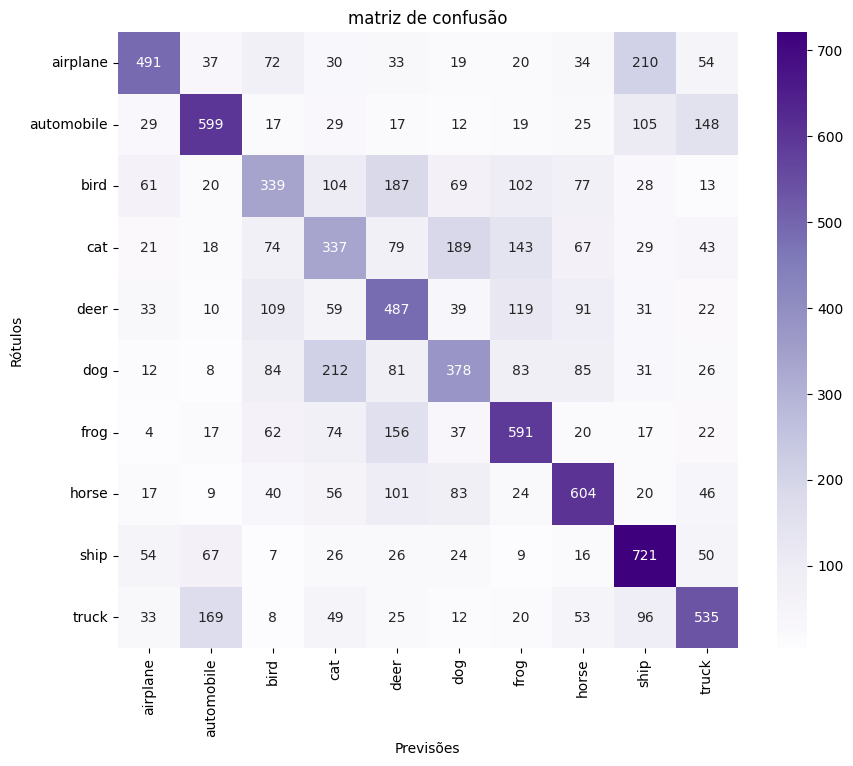

In [ ]:
conf_matrix = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10,8))

sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Purples", xticklabels=dicionario.values(), yticklabels=dicionario.values())

plt.xlabel("Previsões")
plt.ylabel("Rótulos")
plt.title("matriz de confusão")
plt.show()

#**Previsões e Resultados**
Este código visualiza as primeiras 9 imagens do lote de teste, mostrando a previsão do modelo e a etiqueta verdadeira para cada imagem em uma grade 3x3

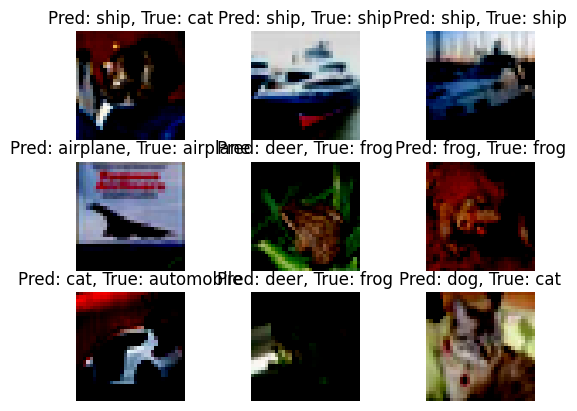

In [ ]:
examples = iter(test_loader)

images, labels = next(examples)

outputs = model(images)

_, predicted = torch.max(outputs, 1)

for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(images[i].permute(1,2,0))
    plt.title(f"Pred: {dicionario[predicted[i].item()]}, True: {dicionario[labels[i].item()]}")
    plt.axis("off")
plt.show()